# Projeto Integrador - AeroMotion Dynamics
## Etapa 1: Diagnóstico, Saneamento e Feature Engineering em Séries Temporais

Este notebook executa a auditoria estrutural dos dados de telemetria das bancadas TURB-101 a TURB-104, trata ruídos de sensores e gera indicadores físicos de degradação.

In [1]:
import os
from pathlib import Path
import sys

# Define e adiciona a raiz do projeto ao path do Python
caminho_raiz = Path.cwd().parent
if str(caminho_raiz) not in sys.path:
  sys.path.append(str(caminho_raiz))

# Altera o diretório de trabalho atual para a raiz do repositório
os.chdir(caminho_raiz)

# Importações de bibliotecas e módulos internos
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_pipeline.feature_engineering import IndustrialFeatureEngineer
from src.data_pipeline.preprocessor import IndustrialDataSanitizer

print(f"Diretório de trabalho ativo: {os.getcwd()}")

Diretório de trabalho ativo: c:\Users\andre_matteussi\Documents\GitHub\aeromotion-predictive-system


## 1. Inspeção Estrutural e Consistência Temporal
Carregamento do dataset `dados_sensores_aeromotion.csv` e validação do intervalo de amostragem de 10 minutos por bancada.

In [2]:
sanitizer = IndustrialDataSanitizer("data/raw/dados_sensores_aeromotion.csv")
df_bruto = sanitizer.carregar_dados()
relatorio_inspecao = sanitizer.inspecionar_estrutura()

print("--- Diagnóstico Estrutural ---")
print(f"Total de registos: {relatorio_inspecao['total_registos']}")
print(f"Equipamentos monitorizados: {relatorio_inspecao['equipamentos']}")
print("\nTaxa de dados em falta inicial:")
for col, total in relatorio_inspecao["nulos_por_coluna"].items():
  print(f"  {col}: {total} nulos")

--- Diagnóstico Estrutural ---
Total de registos: 12000
Equipamentos monitorizados: ['TURB-101', 'TURB-102', 'TURB-103', 'TURB-104']

Taxa de dados em falta inicial:
  timestamp: 0 nulos
  id_equipamento: 0 nulos
  modo_operacao: 0 nulos
  horas_operacao_acumuladas: 0 nulos
  temperatura_mancal_c: 409 nulos
  vibracao_rms_mms: 352 nulos
  pressao_oleo_bar: 328 nulos
  rotacao_rpm: 0 nulos
  emissao_acustica_db: 484 nulos
  corrente_eletrica_amp: 0 nulos
  tipo_falha: 0 nulos


## 2. Tratamento de Ruídos Físicos e Interpolação Temporal
- **Filtro físico**: Remoção de leituras causadas por interferência eletromagnética (como temperaturas de 999.9 °C e vibrações negativas de -99.0 mm/s).
- **Interpolação**: Preenchimento de falhas mantendo a continuidade física individual de cada bancada.

In [3]:
sanitizer.filtrar_ruidos_eletromagneticos()
df_limpo = sanitizer.interpolar_series_temporais(metodo="time")

# Verificação pós-tratamento
print(
    f"Quantidade total de nulos restantes: {df_limpo.isnull().sum().sum()}"
)

Quantidade total de nulos restantes: 0


## 3. Engenharia de Atributos (Feature Engineering)
Criação de métricas de séries temporais para capturar tendências de falha:
- Médias móveis e desvios-padrão móveis com janelas de 1h (6 períodos) e 6h (36 períodos).
- **Severidade Dinâmica**: razão física calculada por $\text{Vibração RMS} / \text{Rotação (RPM)}$.

In [4]:
engineer = IndustrialFeatureEngineer(df_limpo)
df_final = engineer.executar_pipeline()

# Persistência em Parquet para as próximas etapas
df_final.to_parquet("data/processed/features_eng.parquet", index=False)
print("Base de dados final salva com sucesso em 'data/processed/features_eng.parquet'.")
df_final.head()

Base de dados final salva com sucesso em 'data/processed/features_eng.parquet'.


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,vibracao_rms_mms_rolling_mean_1h,vibracao_rms_mms_rolling_std_1h,temperatura_mancal_c_rolling_mean_1h,temperatura_mancal_c_rolling_std_1h,vibracao_rms_mms_rolling_mean_6h,vibracao_rms_mms_rolling_std_6h,temperatura_mancal_c_rolling_mean_6h,temperatura_mancal_c_rolling_std_6h,severidade_dinamica
0,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,2.500000,3.51,2382.7,44.97,18.73,0,2.500000,0.000000,57.830000,0.000000,2.500000,0.000000,57.830000,0.000000,0.001049
1,2026-01-01 01:00:00,TURB-101,Carga_Media,101.4,58.03,2.500000,4.00,2925.2,52.83,27.75,0,2.500000,0.000000,57.930000,0.141421,2.500000,0.000000,57.930000,0.141421,0.000855
2,2026-01-01 01:10:00,TURB-101,Carga_Alta,101.5,75.77,3.718889,4.68,3569.7,63.52,37.74,0,2.906296,0.703726,63.876667,10.300414,2.906296,0.703726,63.876667,10.300414,0.001042
3,2026-01-01 02:30:00,TURB-101,Carga_Media,106.4,64.11,13.470000,4.19,3011.2,49.74,42.56,2,5.547222,5.313013,63.935000,8.411062,5.547222,5.313013,63.935000,8.411062,0.004473
4,2026-01-01 03:30:00,TURB-101,Cruzeiro,109.2,49.55,1.280000,4.08,2477.4,44.98,18.99,0,4.693778,4.981257,61.058000,9.718288,4.693778,4.981257,61.058000,9.718288,0.000517


## 4. Análise Exploratória de Dados (EDA)
Análise de correlação multivariada e visualização da dispersão dos parâmetros operacionais nos modos Cruzeiro, Carga Média e Carga Alta.

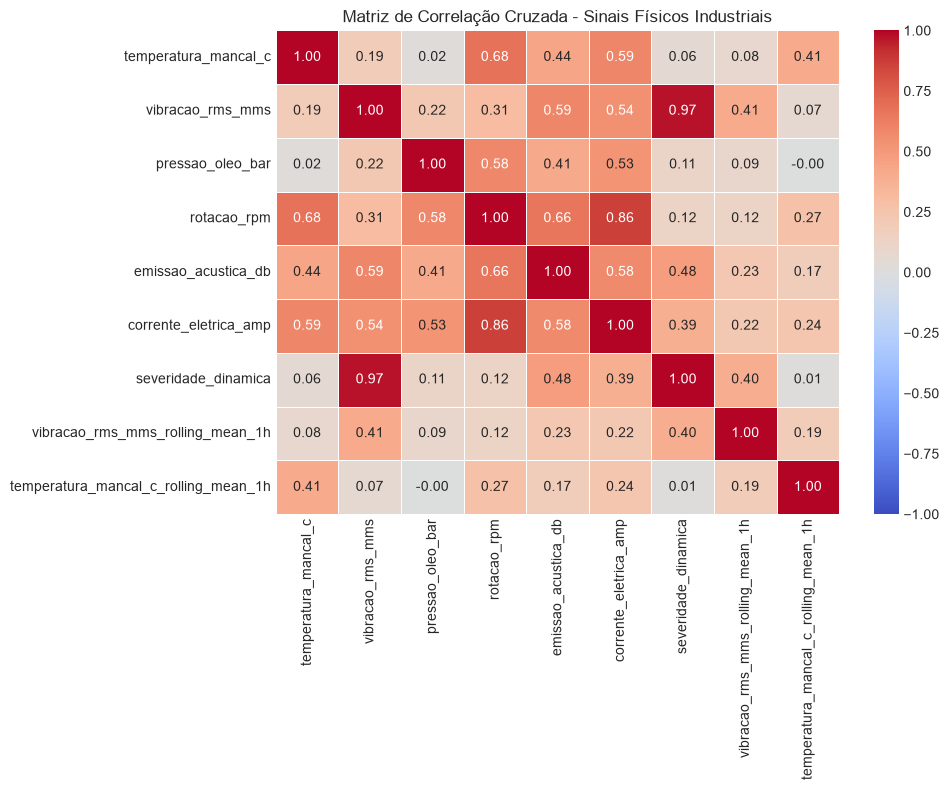

In [5]:
plt.style.use("seaborn-v0_8-whitegrid")

features_analise = [
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
    "severidade_dinamica",
    "vibracao_rms_mms_rolling_mean_1h",
    "temperatura_mancal_c_rolling_mean_1h",
]

plt.figure(figsize=(10, 8))
matriz_corr = df_final[features_analise].corr()
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    "Matriz de Correlação Cruzada - Sinais Físicos Industriais", fontsize=12
)
plt.tight_layout()
plt.show()

C:\Users\andre_matteussi\AppData\Local\Temp\ipykernel_26008\2470472661.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


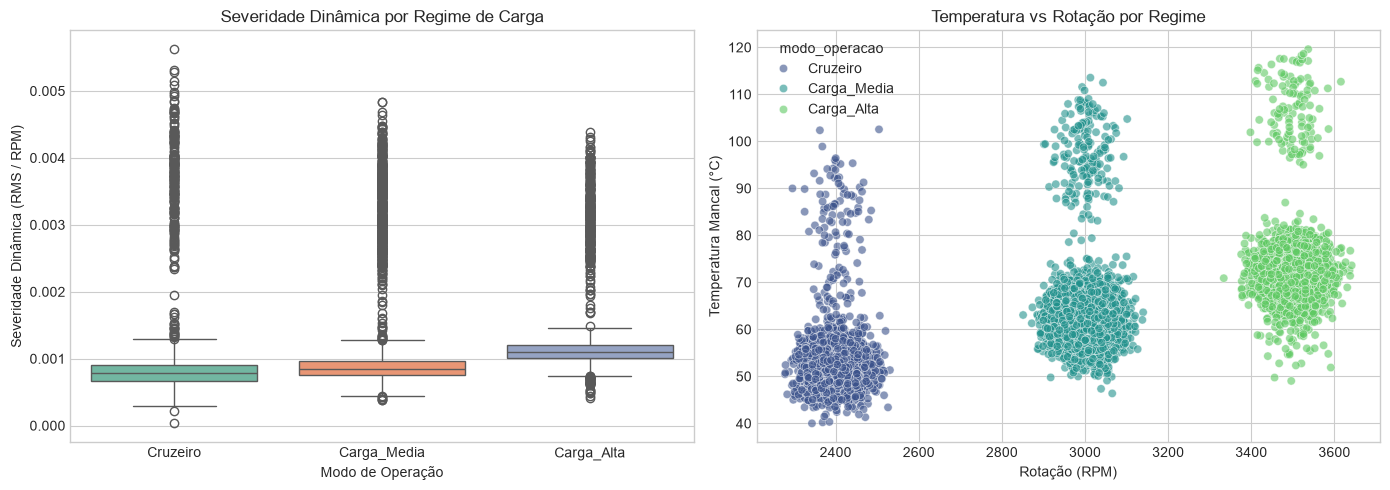

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_final,
    x="modo_operacao",
    y="severidade_dinamica",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Severidade Dinâmica por Regime de Carga")
axes[0].set_xlabel("Modo de Operação")
axes[0].set_ylabel("Severidade Dinâmica (RMS / RPM)")

sns.scatterplot(
    data=df_final,
    x="rotacao_rpm",
    y="temperatura_mancal_c",
    hue="modo_operacao",
    alpha=0.6,
    palette="viridis",
    ax=axes[1],
)
axes[1].set_title("Temperatura vs Rotação por Regime")
axes[1].set_xlabel("Rotação (RPM)")
axes[1].set_ylabel("Temperatura Mancal (°C)")

plt.tight_layout()
plt.show()